In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

prices_df = pd.read_csv('/Users/lautarocardinisilvestri/downloads/Ironhack/Semana 5/amz_uk_price_prediction_dataset 2.csv')


In [33]:
prices_df_full = prices_df.copy()


In [34]:
prices_df = prices_df[(prices_df['price'] >= lower_bound) &
                      (prices_df['price'] <= upper_bound)]


PARTE 1

In [4]:
crosstab = pd.crosstab(prices_df['category'], prices_df['isBestSeller'], normalize='index')
crosstab.sort_values(by=True, ascending=False)


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


In [ ]:
#Se observa que no hay un predominio de best sellers en ninguna categoría, siendo Grocery y Smart Home Security aquellas categorías dond emás se manifieste esta condicion.

In [5]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(prices_df['category'], prices_df['isBestSeller'])
chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi2:", chi2)
print("p-value:", p)


Chi2: 36540.20270061387
p-value: 0.0


In [ ]:
#Siendo p-value, se observa una relación entre la categoría del producto y si es un best seller o no, aunque esta relación no es tan fuerte como para afirmar que la categoría del producto es un factor determinante para ser un best seller.

In [6]:
n = contingency.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape)-1)))
print("Cramér's V:", cramers_v)


Cramér's V: 0.1222829439760564


In [ ]:
#Siendo el índice de Cramer cercano a 0, se ve que la relación entre las variables es débil, lo que refuerza la conclusión de que la categoría del producto no es un factor determinante para ser un best seller.

In [7]:
crosstab_prop = pd.crosstab(
    prices_df['category'],
    prices_df['isBestSeller'],
    normalize='index'
)


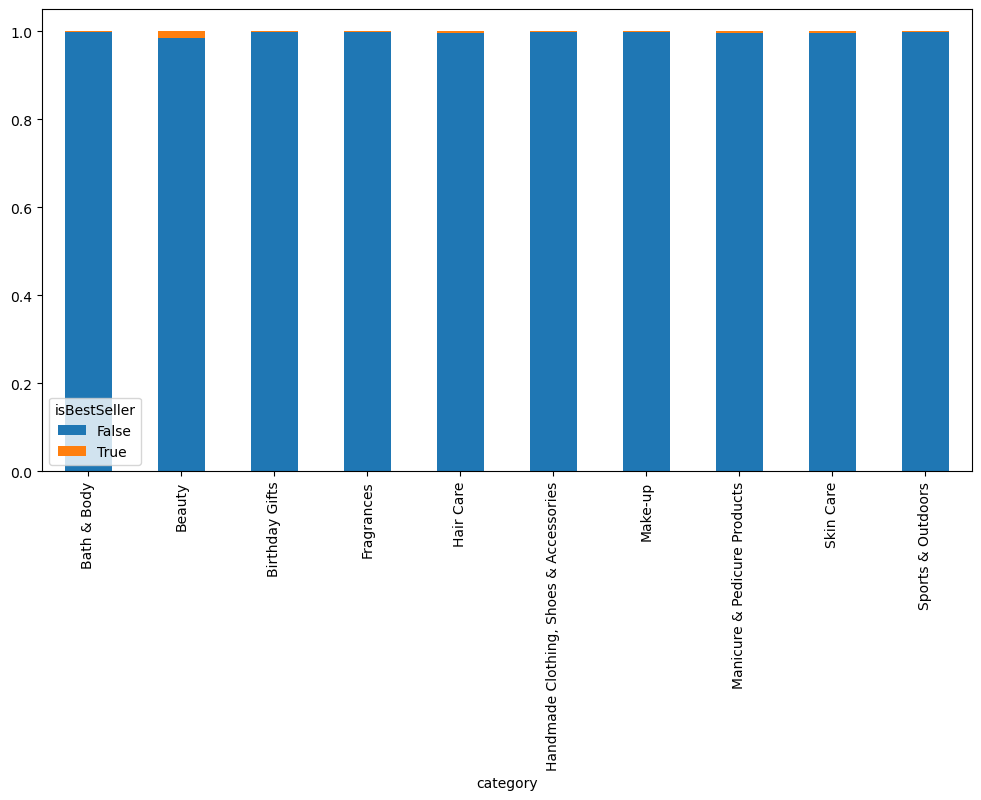

In [10]:
top_categories = prices_df['category'].value_counts().head(10).index

filtered_df = prices_df[prices_df['category'].isin(top_categories)]

crosstab_prop = pd.crosstab(
    filtered_df['category'],
    filtered_df['isBestSeller'],
    normalize='index'
)

crosstab_prop.plot(kind='bar', stacked=True, figsize=(12,6))
plt.show()


El gráfico de barras apiladas muestra lo que se ha explicado en los primeros apartados. La proporción de productos best seller es muy reducida en todas las categorías analizadas. No se observan diferencias relevantes entre categorías, lo que sugiere que la categoría best seller no parece concentrarse en una variable específica.

PARTE 2

In [11]:
Q1 = prices_df['price'].quantile(0.25)
Q3 = prices_df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = prices_df[
    (prices_df['price'] >= lower_bound) &
    (prices_df['price'] <= upper_bound)
]


Se eliminaron outliers utilizando el método del rango intercuartílico (IQR), considerando como outliers aquellos precios por debajo de Q1 y encima de Q3 

In [12]:
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

filtered_df = df_no_outliers[
    df_no_outliers['category'].isin(top_20_categories)
]


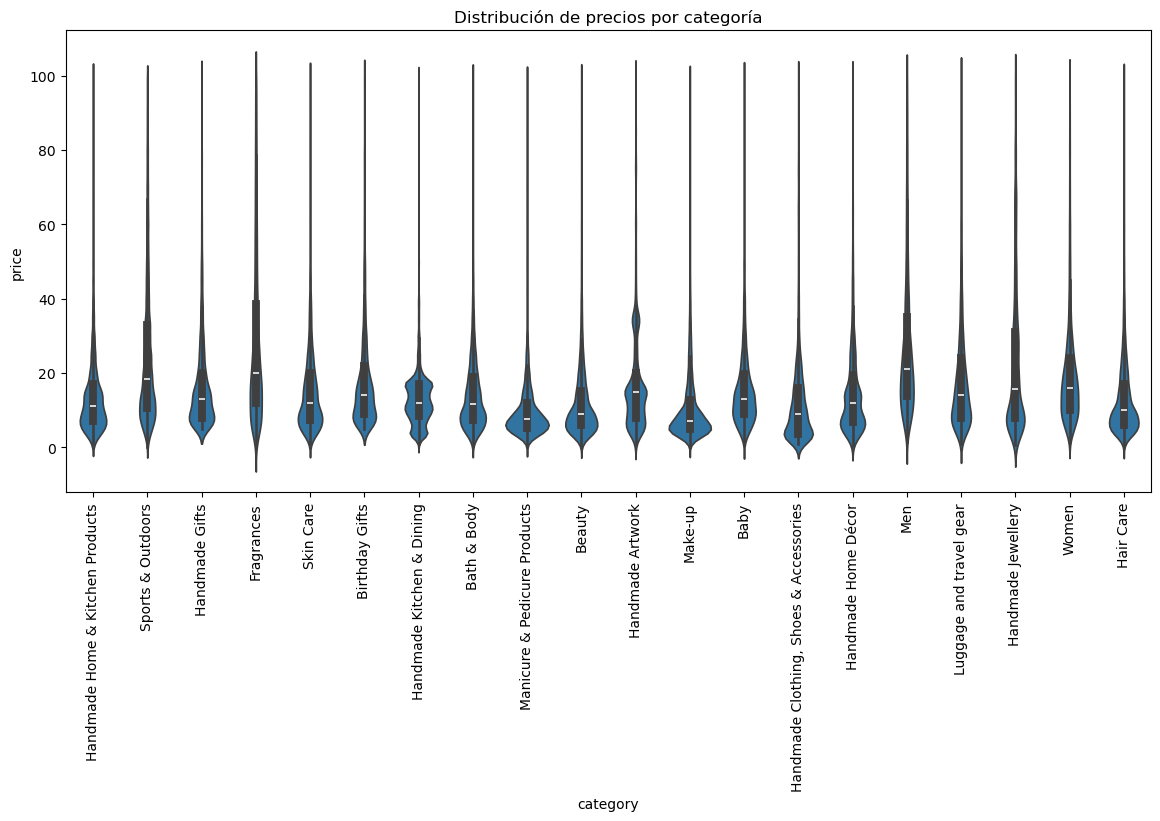

In [13]:
plt.figure(figsize=(14,6))
sns.violinplot(
    data=filtered_df,
    x='category',
    y='price'
)

plt.xticks(rotation=90)
plt.title('Distribución de precios por categoría')
plt.show()


In [15]:
median_prices = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_prices.head(5)


category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

In [22]:
mean_prices = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

mean_prices.head(10)


category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

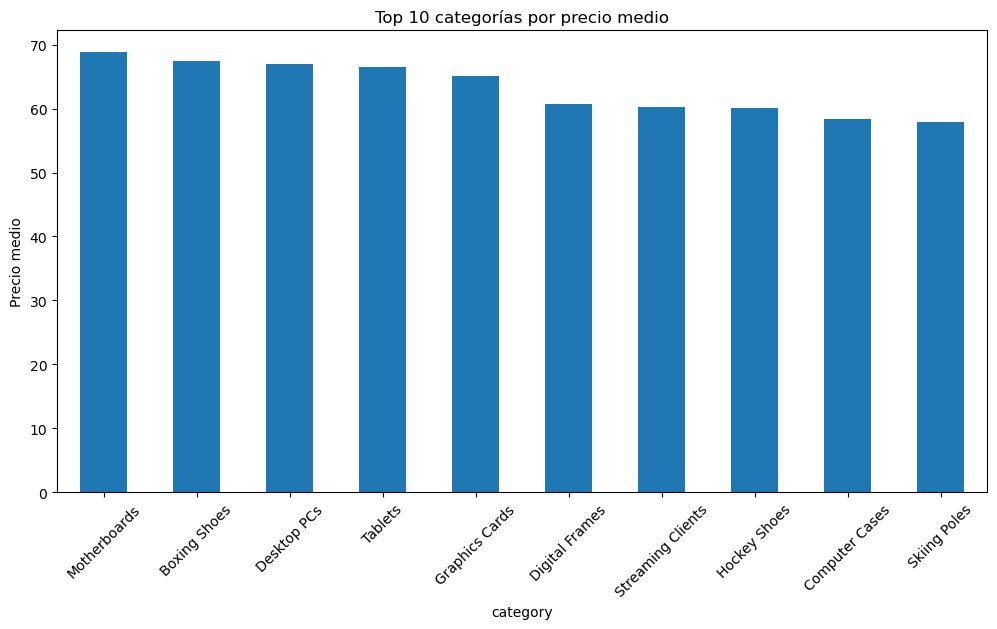

In [23]:
top10_mean = mean_prices.head(10)

plt.figure(figsize=(12,6))
top10_mean.plot(kind='bar')
plt.title('Top 10 categorías por precio medio')
plt.ylabel('Precio medio')
plt.xticks(rotation=45)
plt.show()


Se calcula las categorías con los valores medianos más top, para reconocer cuál son aquellos productos que tienden a ser los más costosos.
Aunque el gráfico se realizó con las categorías más frecuentes para mejorar la visualización, el cálculo de la mediana se realizó sobre todas las categorías (sin filtrado). La categoría con mayor mediana de precio es la de ordenadores de escritorio, lo que indica que sus productos tienden a posicionarse en un rango de precios más elevado, seguido por zapatillas de boxeo, tablets, y componentes de hardware.

Los artículos informáticos son aquellos en los que los precios son más elevados, respecto a los demás, siguiéndoles, por ejemplo, ropa o artículos deportivos

In [24]:
median_ratings = (
    df_no_outliers
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

median_ratings.head(10)


category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

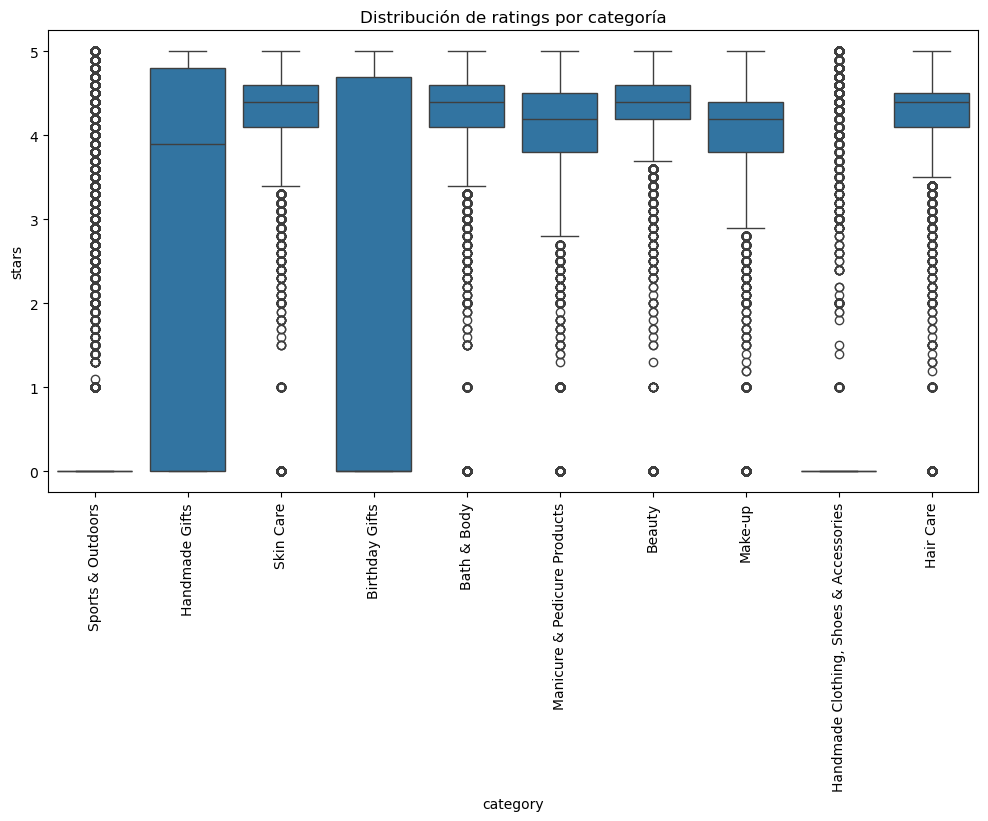

In [26]:
top10_categories = df_no_outliers['category'].value_counts().head(10).index

filtered_df = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

plt.figure(figsize=(12,6))
sns.boxplot(data=filtered_df, x='category', y='stars')
plt.xticks(rotation=90)
plt.title('Distribución de ratings por categoría')
plt.show()


El análisis de las valoraciones muestra que:

    La mayoría de categorías presentan medianas de rating altas (entre 4.2 y 4.5).

    La variabilidad entre categorías es relativamente baja.

    Las diferencias en satisfacción del cliente entre categorías no son muy marcadas.

Esto sugiere que:

    La calidad percibida es consistentemente alta en la mayoría del catálogo.

    El rating no parece depender fuertemente de la categoría.

    Las categorías no muestran brechas significativas en experiencia del cliente.

PARTE 3

In [27]:
corr = prices_df[['price', 'stars']].corr()
corr


,price,stars
price,1.000000,-0.124907
stars,-0.124907,1.000000


No existe una relación lineal significativa entre el precio del producto y su valoración, por lo que pagar más no garantiza mejores ratings.
Por el contrario, productos más caros no necesariamente reciben mejores valoraciones, e incluso podrían estar más expuestos a críticas más exigentes.

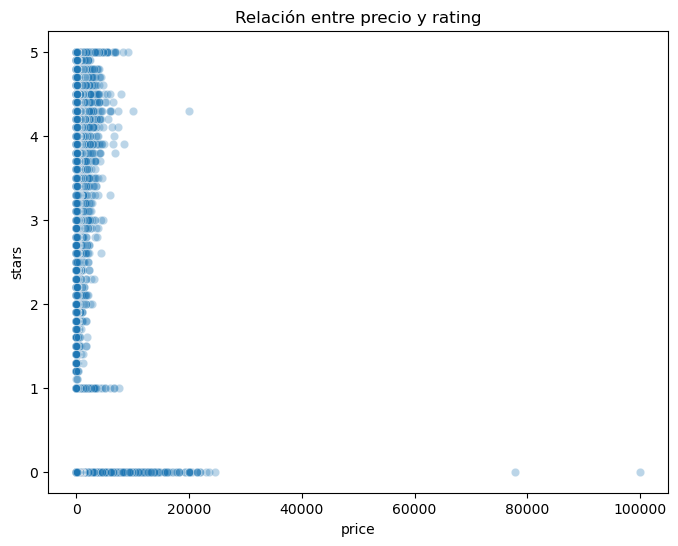

In [28]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=prices_df, x='price', y='stars', alpha=0.3)
plt.title('Relación entre precio y rating')
plt.show()


Al haber patrones horizontales, vemos lo mencionado anteriormente, que no hay una relación directa entre el precio de un producto con su rating recibido.

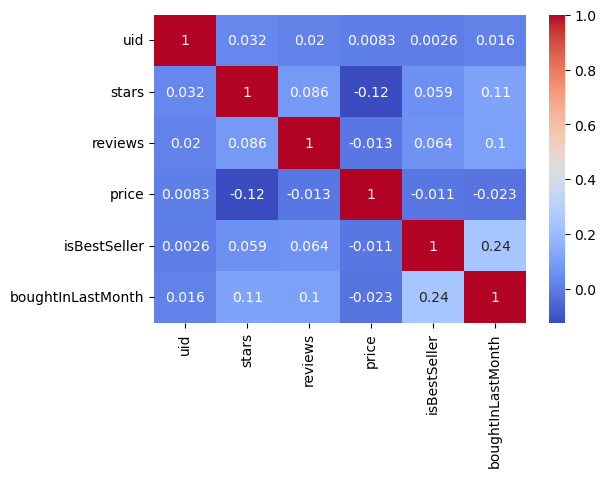

In [29]:
plt.figure(figsize=(6,4))
sns.heatmap(prices_df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()


Los best sellers sí se relacionan con ventas recientes, en este caso. 
Las valoraciones no están fuertemente relacionadas con el precio
Tampoco están fuertemente relacionadas con el volumen de reviews

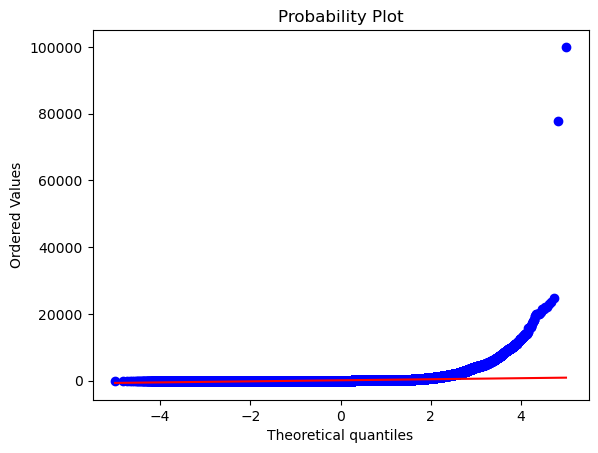

In [30]:
import scipy.stats as stats

stats.probplot(prices_df['price'], dist="norm", plot=plt)
plt.show()


El análisis de distribución revela que los precios presentan una fuerte asimetría positiva y no siguen una distribución normal, lo que sugiere que el mercado contiene una gran cantidad de productos de bajo costo y pocos productos extremadamente caros.

Desde una perspectiva de negocio, esto indica que aumentar el precio no garantiza una mejora en la percepción del cliente, y que otros factores (marca, categoría, calidad percibida o volumen de reseñas) probablemente juegan un papel más determinante en la valoración del producto.

In [ ]:
#BONUS

In [31]:
prices_df = prices_df[(prices_df['price'] >= lower_bound) & 
                      (prices_df['price'] <= upper_bound)]


In [35]:
corr_full = prices_df_full[['price', 'stars']].corr()
corr_full



,price,stars
price,1.000000,-0.077673
stars,-0.077673,1.000000


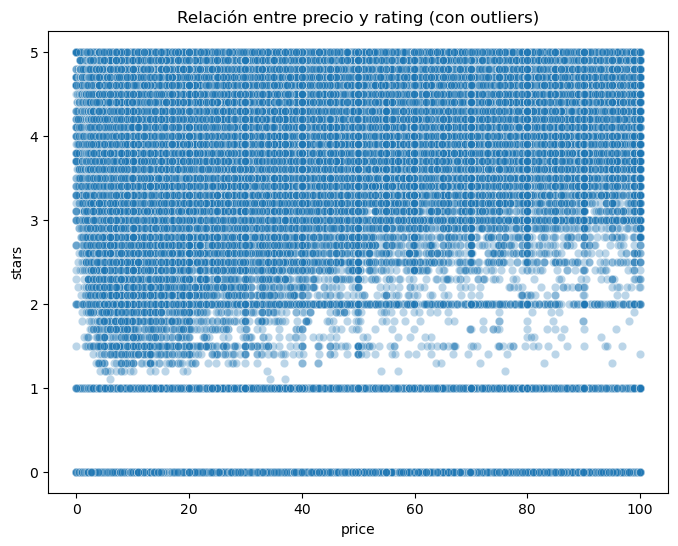

In [36]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=prices_df_full, x='price', y='stars', alpha=0.3)
plt.title("Relación entre precio y rating (con outliers)")
plt.show()


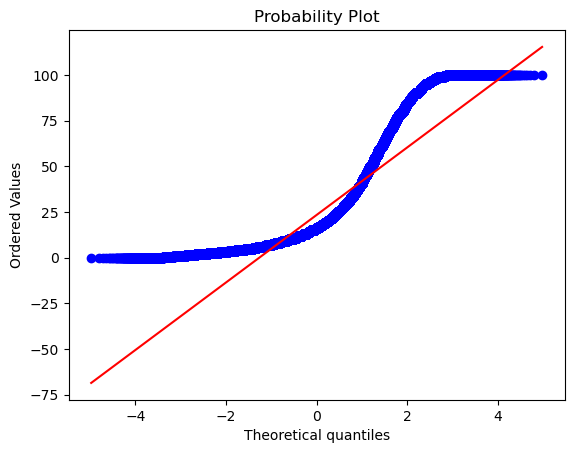

In [37]:
stats.probplot(prices_df_full['price'], dist="norm", plot=plt)
plt.show()


Al repetir el análisis sin eliminar los outliers, los resultados se mantienen consistentes.
La relación entre precio y rating sigue siendo débil y ligeramente negativa, lo que confirma que los productos más caros no tienden a recibir mejores valoraciones.
Los outliers afectan principalmente a la escala visual y a la dispersión, pero no alteran las conclusiones fundamentales del análisis.
Asimismo, incluso tras eliminar valores extremos, la distribución del precio continúa siendo asimétrica y no normal, lo que refuerza la necesidad de utilizar medidas robustas en el análisis.